In [8]:
# @title Imports {vertical-output: true}

import collections
import os

from etils import epath
from IPython.display import HTML
import matplotlib.pyplot as plt
from ml_collections import config_dict
import numpy as np
import tensorflow as tf
import tqdm

# perch-hoplite: the agile modeling workflow.
from perch_hoplite.agile import audio_loader
from perch_hoplite.agile import classifier
from perch_hoplite.agile import classifier_data
from perch_hoplite.agile import colab_utils
from perch_hoplite.agile import embed
from perch_hoplite.agile import embedding_display
from perch_hoplite.agile import ingest_annotations
from perch_hoplite.agile import source_info
from perch_hoplite.db import brutalism
from perch_hoplite.db import interface
from perch_hoplite.db import score_functions
from perch_hoplite.db import search_results
from perch_hoplite.zoo import model_configs

print('TensorFlow version :', tf.__version__)
print('NumPy version      :', np.__version__)

# A GPU makes the embedding step considerably faster. Every other step in this
# tutorial is quick on CPU, so a CPU-only runtime is perfectly usable.
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  print(f'GPU available      : yes ({len(gpus)} device(s))')
else:
  print('GPU available      : no (CPU only - this is fine for this tutorial)')

TensorFlow version : 2.22.0-rc0
NumPy version      : 2.5.4
GPU available      : no (CPU only - this is fine for this tutorial)


In [39]:
from perch_hoplite.db import sqlite_usearch_impl


db_path = './content/osa_db'
db = sqlite_usearch_impl.SQLiteUSearchDB.create(db_path=db_path)

configs = config_dict.ConfigDict(db.get_metadata(None))
audio_sources = source_info.AudioSources.from_config_dict(config = configs.audio_sources)
WINDOW_SIZE_S = configs.model_config.model_config.window_size_s
SAMPLE_RATE = configs.model_config.model_config.sample_rate
configs


audio_sources:
  audio_globs:
  - base_path: ./data/audio
    dataset_name: silencio
    file_glob: '*/*.wav'
    max_shards_per_file: null
    min_audio_len_s: 1.0
    shard_len_s: 60.0
    target_sample_rate_hz: -2
  - base_path: ./data/grillos/
    dataset_name: grillos
    file_glob: '*/*.wav'
    max_shards_per_file: null
    min_audio_len_s: 1.0
    shard_len_s: 60.0
    target_sample_rate_hz: -2
  - base_path: ./data/SWIFT/
    dataset_name: SWIFT
    file_glob: '*/*.wav'
    max_shards_per_file: null
    min_audio_len_s: 1.0
    shard_len_s: 60.0
    target_sample_rate_hz: -2
model_config:
  embedding_dim: 1280
  logits_idxes: null
  logits_key: null
  model_config:
    hop_size_s: 5.0
    model_path: ''
    sample_rate: 32000
    tfhub_path: google/bird-vocalization-classifier/tensorFlow2/bird-vocalization-classifier
    tfhub_version: 8
    window_size_s: 5.0
  model_key: taxonomy_model_tf
usearch_config:
  dtype: float16
  embedding_dim: 1280
  expansion_add: 256
  expansion

In [40]:
# @title Define the target label {vertical-output: true}

# @markdown The eBird species code for the Wood Thrush.
target_label = 'DENEBR'  # @param {type: 'string'}
'''
Possible target labels
SCIBOU *
DENEBR *
BOAROS *

ELAPER
ENGPUS
DENMIC
LEPFRA
'''
annotator_id = 'testing'

# Loads the audio behind a search result so we can plot and play it.
audio_filepath_loader = audio_loader.make_filepath_loader(
    audio_sources=audio_sources,
    window_size_s=WINDOW_SIZE_S,
    sample_rate_hz=SAMPLE_RATE,
)

print('Target label :', target_label)
print('Annotator id :', annotator_id)

Target label : DENEBR
Annotator id : testing


In [12]:
# @title Prepare the labeled data {vertical-output: true}

# Check that labels exist before doing anything else. Forgetting to click the
# label buttons, or forgetting to run the save cell, is the most common thing
# go wrong in this notebook - and the error it otherwise produces is useless.
existing_labels = db.get_all_labels()



label_counts = db.count_each_label()
print('Labels in the database:')
for label, count in label_counts.items():
  print(f'  {label:12s} {count}')



# @markdown Fraction of labeled examples used for training; the rest are held
# @markdown out to evaluate the model. With ~10 positives, 0.8 holds out two
# @markdown of them - the minimum this library needs to compute every metric.
train_ratio = 0.8  # @param {type: 'number'}

# @markdown Batch sizes for training and for weak negatives.
batch_size = 128  # @param {type: 'number'}
weak_negatives_batch_size = 128  # @param {type: 'number'}

data_manager = classifier_data.AgileDataManager(
    target_labels=None,  # auto-populated from the labels in the database
    db=db,
    train_ratio=train_ratio,
    min_eval_examples=1,
    batch_size=batch_size,
    weak_negatives_batch_size=weak_negatives_batch_size,
    rng=np.random.default_rng(seed=5),
)

print('\nTraining for target labels:', data_manager.get_target_labels())
train_ids, eval_ids = data_manager.get_train_test_split()
print(f'Training examples : {len(train_ids)}')
print(f'Held-out examples : {len(eval_ids)}')



Labels in the database:
  BOAROS       45
  DENEBR       42
  LEPINS       23
  PHYVIT       25
  SCIBOU       27

Training for target labels: ('BOAROS', 'DENEBR', 'LEPINS', 'PHYVIT', 'SCIBOU')
Training examples : 303
Held-out examples : 72


In [13]:
# @title Classifier hyperparameters {vertical-output: true}

# @markdown These defaults work well and should not need tuning.
learning_rate = 1e-3  # @param {type: 'number'}
num_train_steps = 128  # @param {type: 'number'}

# @markdown How much to trust unlabeled results as negatives. Low by design:
# @markdown an unlabeled result is a guess, not an observation.
weak_neg_weight = 0.05  # @param {type: 'number'}

print(f'learning rate    : {learning_rate}')
print(f'training steps   : {num_train_steps}')
print(f'weak neg weight  : {weak_neg_weight}')

learning rate    : 0.001
training steps   : 128
weak neg weight  : 0.05


In [14]:
# @title Train the linear classifier {vertical-output: true}

linear_classifier, eval_scores = classifier.train_linear_classifier(
    data_manager=data_manager,
    learning_rate=learning_rate,
    weak_neg_weight=weak_neg_weight,
    num_train_steps=num_train_steps,
)

print('\nTraining complete.')

Loss 0.02057865: 100%|██████████| 128/128 [00:05<00:00, 23.06it/s]


Training complete.


In [15]:
# @title Show the metrics {vertical-output: true}

import math


def _fmt(value):
  """Format a metric, making 'could not be computed' explicit."""
  if value is None or (isinstance(value, float) and math.isnan(value)):
    return 'not computable'
  return f'{value:.3f}'


top1 = eval_scores['top1_acc']
rocauc = eval_scores['roc_auc']
cmap = eval_scores['cmap']

print(f'top-1 accuracy : {_fmt(top1)}')
print(f'ROC-AUC        : {_fmt(rocauc)}')
print(f'cMAP           : {_fmt(cmap)}')

print('\nLabels used for training:')
for label, count in db.count_each_label().items():
  print(f'  {label:12s} {count}')

def _is_nan(v):
  return v is None or (isinstance(v, float) and math.isnan(v))





# Save the classifier so it can be reused without retraining.
classifier_path = os.path.join(db_path, 'agile_classifier.pt')
linear_classifier.save(classifier_path)
print(f'\nClassifier saved to {classifier_path}')

top-1 accuracy : 0.952
ROC-AUC        : 0.976
cMAP           : 0.756

Labels used for training:
  BOAROS       45
  DENEBR       42
  LEPINS       23
  PHYVIT       25
  SCIBOU       27

Classifier saved to ./content/osa_db\agile_classifier.pt


In [41]:
# @title Find new examples using the classifier {vertical-output: true}

# @markdown Number of results to surface.
num_results = 5  # @param {type: 'number'}

# @markdown If checked, look for examples the model is *uncertain* about
# @markdown (margin sampling) rather than the ones it is most confident about.
margin_sampling = True  # @param {type: 'boolean'}

# @markdown The logit to aim for when margin sampling. 0.0 is the decision
# @markdown boundary - where the model is maximally unsure.
margin_target_score = 0.0  # @param {type: 'number'}

# @markdown How many database entries to search over.
sample_size = 1_000_000  # @param {type: 'number'}

target_label_idx = data_manager.get_target_labels().index(target_label)
class_query = linear_classifier.beta[:, target_label_idx]
bias = linear_classifier.beta_bias[target_label_idx]

score_fn = score_functions.get_score_fn(
    'dot', bias=bias,
    target_score=margin_target_score if margin_sampling else None)

results = brutalism.threaded_brute_search(
    db, class_query, num_results, score_fn=score_fn, sample_size=sample_size)

print(f'Returned {len(results.search_results)} results.')
print('Now label these below, then retrain. This is the active learning loop.')

Returned 5 results.
Now label these below, then retrain. This is the active learning loop.


In [42]:
results.search_results

[SearchResult(window_id=np.int64(25435), sort_score=np.float32(-0.0034514293), display_label_type=None),
 SearchResult(window_id=np.int64(23933), sort_score=np.float32(-0.0022350177), display_label_type=None),
 SearchResult(window_id=np.int64(23976), sort_score=np.float32(-0.001905784), display_label_type=None),
 SearchResult(window_id=np.int64(24001), sort_score=np.float32(-6.450713e-05), display_label_type=None),
 SearchResult(window_id=np.int64(22970), sort_score=np.float32(-0.0010343045), display_label_type=None)]

In [43]:
results.search_results
windows = [db.get_window(w.window_id) for w in results.search_results]
annotations = [db.get_window_annotations(w.window_id) for w in results.search_results]
recordings = [db.get_recording(r.recording_id) for r in windows]
deploys = [db.get_deployment(d.deployment_id) for d in recordings]
deploys

examples = {}

for i, result in enumerate(results.search_results):
    info={}
    info["window_id"] = int(result.window_id)
    info["score"] = float(result.sort_score)
    info["recording_id"] = windows[i].recording_id
    info["offsets"] = windows[i].offsets
    info["uri"] = recordings[i].filename
    info["dataset_name"] = deploys[i].project

    examples[i] = info

examples

{0: {'window_id': 25435,
  'score': -0.003451429307460785,
  'recording_id': 633,
  'offsets': [35.0, 40.0],
  'uri': 'sw2/1Jsw2_20261009_014000.wav',
  'dataset_name': 'grillos'},
 1: {'window_id': 23933,
  'score': -0.002235017716884613,
  'recording_id': 508,
  'offsets': [25.0, 30.0],
  'uri': 'sw1/1Jsw1_20260919_224000.wav',
  'dataset_name': 'grillos'},
 2: {'window_id': 23976,
  'score': -0.001905784010887146,
  'recording_id': 512,
  'offsets': [0.0, 5.0],
  'uri': 'sw1/1Jsw1_20260920_000000.wav',
  'dataset_name': 'grillos'},
 3: {'window_id': 24001,
  'score': -6.45071268081665e-05,
  'recording_id': 514,
  'offsets': [5.0, 10.0],
  'uri': 'sw1/1Jsw1_20260920_004000.wav',
  'dataset_name': 'grillos'},
 4: {'window_id': 22970,
  'score': -0.0010343044996261597,
  'recording_id': 428,
  'offsets': [10.0, 15.0],
  'uri': 'sw1/1Jsw1_20260917_225400.wav',
  'dataset_name': 'grillos'}}

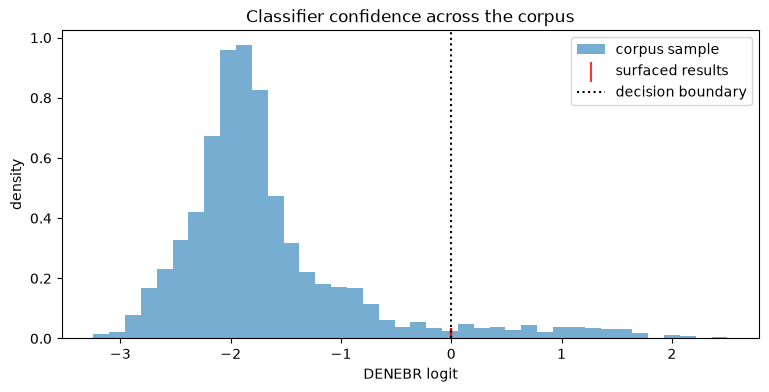

6.2% of sampled windows score above the decision boundary.
If that number looks implausibly high for one species in one forest, it probably is - a useful early warning of a poor classifier.


In [44]:
# @title Plot the classifier logits {vertical-output: true}

scores = brutalism.get_random_embedding_scores(
    db,
    class_query,
    score_fn=score_functions.get_score_fn('dot', bias=bias),
    sample_size=2048,
    rng_seed=42,
)

plt.figure(figsize=(9, 4))
plt.hist(scores, bins=40, density=True, alpha=0.6, label='corpus sample')

hit_scores = [r.sort_score for r in results.search_results]
plt.scatter(hit_scores, np.zeros_like(hit_scores), marker='|',
            color='r', alpha=0.8, s=200, label='surfaced results')
plt.axvline(0.0, color='k', linestyle=':', label='decision boundary')

plt.xlabel(f'{target_label} logit')
plt.ylabel('density')
plt.title('Classifier confidence across the corpus')
plt.legend()
plt.show()

above = (scores > 0).mean()
print(f'{above * 100:.1f}% of sampled windows score above the decision '
      'boundary.')
print('If that number looks implausibly high for one species in one forest, '
      'it probably is - a useful early warning of a poor classifier.')

In [47]:
display_results.members

[EmbeddingDisplay(window_id=24001, recording_id=514, offsets=[5.0, 10.0], dataset_name='grillos', uri='sw1/1Jsw1_20260920_004000.wav', offset_s=5.0, score=np.float32(-6.450713e-05), widgets={'DENEBR': Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle())}, sample_rate_hz=32000, frame_rate=100, audio=array([-0.00188324,  0.00164098,  0.01810865, ..., -0.00245841,
        -0.00315269, -0.01378887], shape=(160000,), dtype=float32), spectrogram=array([[0.11698234, 0.12146257, 0.10338431, ..., 0.21962935, 0.17169365,
         0.12372453],
        [0.28696291, 0.3220937 , 0.21580217, ..., 0.2175038 , 0.20661127,
         0.16394336],
        [0.56543262, 0.47272933, 0.21526603, ..., 0.21442591, 0.19841543,
         0.17429305],
        ...,
        [0.2410394 , 0.1524373 , 0.11466633, ..., 0.22815767, 0.2088116 ,
         0.19354167],
        [0.19575592, 0.08980887, 0.05331365, ..., 0.2517417 , 0.20957915,
         0.17484783],
        [0.14394912, 0.118276

Page 1 of 1
--------------------------------------------------------------------------------



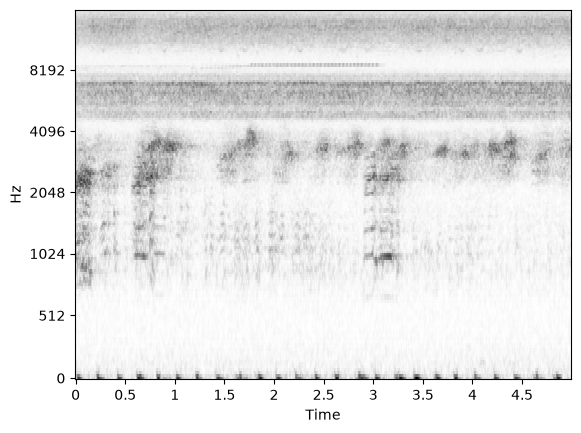

dataset name : grillos
source uri   : sw1/1Jsw1_20260920_004000.wav
offset_s     : 5.00
score        : -0.00


GridspecLayout(children=(Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


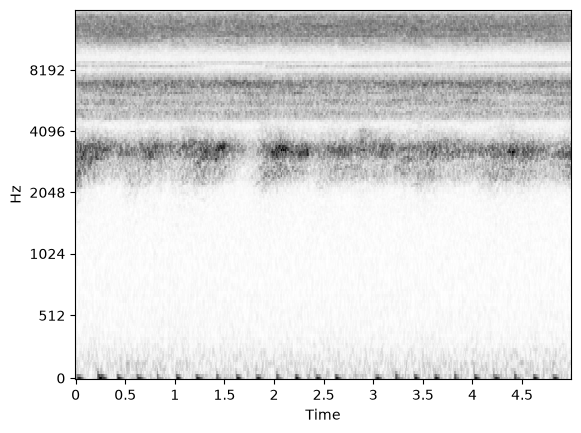

dataset name : grillos
source uri   : sw1/1Jsw1_20260917_225400.wav
offset_s     : 10.00
rank         : 1
score        : -0.00


GridspecLayout(children=(Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


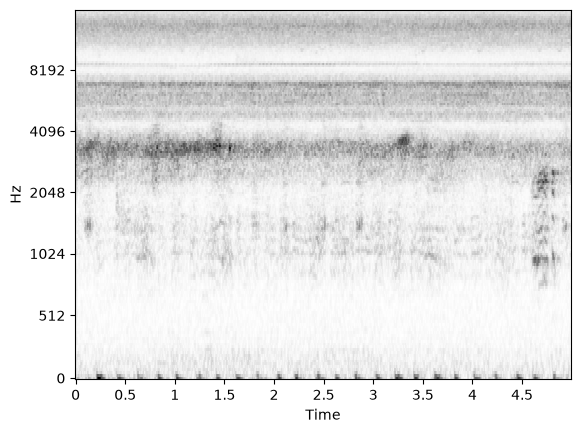

dataset name : grillos
source uri   : sw1/1Jsw1_20260920_000000.wav
offset_s     : 0.00
rank         : 2
score        : -0.00


GridspecLayout(children=(Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


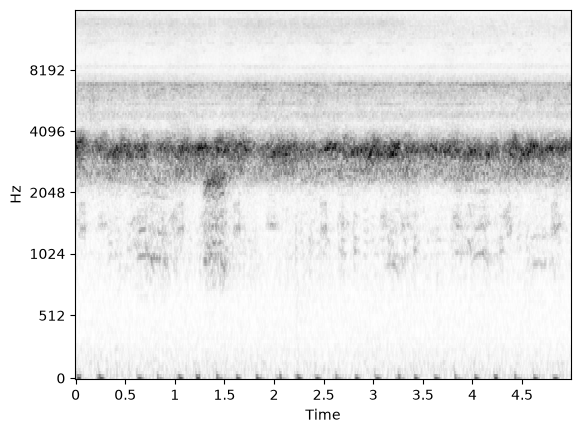

dataset name : grillos
source uri   : sw1/1Jsw1_20260919_224000.wav
offset_s     : 25.00
rank         : 3
score        : -0.00


GridspecLayout(children=(Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


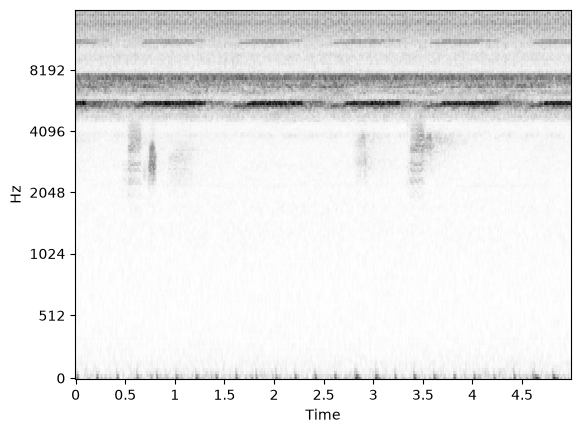

dataset name : grillos
source uri   : sw2/1Jsw2_20261009_014000.wav
offset_s     : 35.00
rank         : 4
score        : -0.00


GridspecLayout(children=(Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------
Page 1 of 1


Button(description='Prev Page', style=ButtonStyle())

Button(description='Next Page', style=ButtonStyle())

In [45]:
# @title Display the new results for labeling {vertical-output: true}

display_results = embedding_display.EmbeddingDisplayGroup.from_search_results(
    results,
    db,
    sample_rate_hz=SAMPLE_RATE,
    frame_rate=100,
    audio_loader=audio_filepath_loader,
)
display_results.display(positive_labels=[target_label])

#### Add selected results to the labeled data

As before, once we've annotated the examples from the previous cell, we'll save them in the `labeled_data_dir`.

In [38]:
# @title Save the new labels {vertical-output: true}

print('Annotations before saving :', len(db.get_all_annotations()))

db.insert_annotations(
    display_results.harvest_labels(annotator_id),
    handle_duplicates='skip',
)
db.commit()

print('Annotations after saving  :', len(db.get_all_annotations()))
print('\nNow go back and retrain the classifier with this extra data.')

Annotations before saving : 28
Annotations after saving  : 31

Now go back and retrain the classifier with this extra data.
